# Comparaison des projections 2D du jeu Iris par ACP et par LDA

Le jeu Iris décrit 3 espèces d'iris (setosa, versicolor et virginica) par 4 attributs : longueur du sépale, largeur du sépale, longueur du pétale et largeur du pétale.

L'analyse en composantes principales (ACP, *PCA* en anglais) appliquée à ces données identifie les combinaisons d'attributs (composantes principales, ou directions dans l'espace des variables) qui expliquent le plus de variance dans les données. On affiche ici les exemples sur les 2 premières composantes principales.

L'analyse discriminante linéaire (LDA) cherche les axes qui maximisent le rapport variance inter-classes / variance intra-classes. Contrairement à l'ACP, la LDA est une méthode supervisée, qui utilise les classes connues ; elle donne au plus C − 1 axes pour C classes.

Ce notebook s'appuie largement sur un [exemple de code de scikit-learn](https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_vs_lda.html).

## Les données

Les 4 attributs sont centrés et réduits, pour que chacun ait le même poids dans l'ACP.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

iris = load_iris()
print(iris.feature_names)
X = StandardScaler().fit_transform(iris.data)
y = iris.target
target_names = iris.target_names
colors = ["navy", "turquoise", "darkorange"]


def plot_projection(Z, title):
  # Trace une projection 2D, un point par fleur, une couleur par espèce
  plt.figure()
  for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(Z[y == i, 0], Z[y == i, 1], color=color, alpha=0.8, label=target_name)
  plt.legend(loc="best", shadow=False, scatterpoints=1)
  plt.title(title)
  plt.show()

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## ACP

Part de variance expliquée par chaque composante : [0.73 0.23]


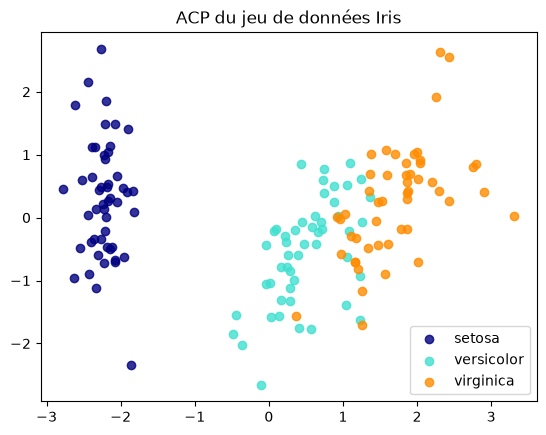

In [2]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print(
  f"Part de variance expliquée par chaque composante : {pca.explained_variance_ratio_.round(2)}"
)
plot_projection(X_pca, "ACP du jeu de données Iris")

Les deux premières composantes gardent 73 % et 23 % de la variance, 96 % à elles deux. Setosa est à part ; versicolor et virginica se chevauchent un peu : l'ACP ne connaît pas les espèces.

## LDA

Part de la séparation portée par chaque axe : [0.99 0.01]


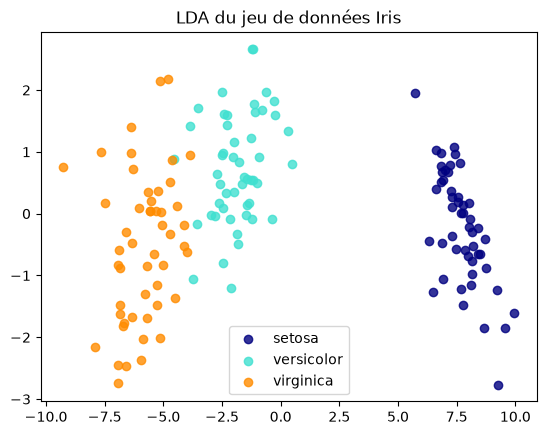

In [3]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print(
  f"Part de la séparation portée par chaque axe : {lda.explained_variance_ratio_.round(2)}"
)
plot_projection(X_lda, "LDA du jeu de données Iris")

La LDA donne 2 axes, C − 1 pour 3 espèces. Son `explained_variance_ratio_` est la part de la séparation entre classes que porte chaque axe (99 % et 1 %), pas une part de la variance des données. Sur le premier axe, versicolor et virginica se chevauchent moins que sur l'ACP.

## Comparaison

- L'ACP, non supervisée, garde la plus grande variance des mesures ; la LDA, supervisée, sépare les classes qu'on lui donne.
- La LDA sépare mieux versicolor et virginica, parce qu'elle utilise les espèces.
- Sur Iris, les deux cartes se ressemblent, parce que la taille des pétales, l'axe de plus grande variance, est aussi ce qui distingue les espèces : ce n'est pas toujours le cas.